# Customer Segmentation & Transaction Analytics

Financial Services Analytics Platform — Python Analysis Notebook

This notebook takes the raw transaction data (from PostgreSQL/CSV), cleans it, engineers features, builds an RFM-based customer segmentation, detects outliers, calculates executive KPIs, and exports clean datasets for Tableau.


# Steps

Load & inspect data

Data cleaning & missing value handling

Feature engineering

Outlier detection

RFM customer segmentation

KPI calculation

Export processed data for Tableau

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (10, 5)

DATA_DIR = "/Users/prettygoyal/downloads/financial-analytics-project/data"


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
DATA_DIR = "/content/drive/MyDrive/data"

In [6]:
customers = pd.read_csv(f"{DATA_DIR}/customers.csv", parse_dates=["date_of_birth", "signup_date"])
cards = pd.read_csv(f"{DATA_DIR}/cards_fixed.csv", parse_dates=["issue_date", "expiry_date"])
merchants = pd.read_csv(f"{DATA_DIR}/merchants.csv")
categories = pd.read_csv(f"{DATA_DIR}/merchant_categories.csv")
transactions = pd.read_csv(f"{DATA_DIR}/transactions_fixed.csv", parse_dates=["transaction_date"])

print(customers.shape, cards.shape, merchants.shape, categories.shape, transactions.shape)
transactions.head()

(15000, 11) (18000, 8) (600, 6) (15, 3) (500000, 9)


,transaction_id,card_id,customer_id,merchant_id,transaction_date,transaction_amount,transaction_type,transaction_status,is_fraud
0,1,4820,2128,29,2025-07-24 14:35:00,12.32,POS,Approved,0
1,2,3034,4911,333,2025-03-13 14:37:00,30.55,POS,Approved,0
2,3,4011,1007,210,2025-08-12 06:56:00,75.42,ATM,Approved,0
3,4,15467,14108,470,2025-04-20 16:44:00,59.24,Online,Approved,0
4,5,5781,14720,560,2026-04-22 19:57:00,14.83,Online,Approved,0


In [7]:
transactions.info()
transactions.describe(include='all').T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      500000 non-null  int64         
 1   card_id             500000 non-null  int64         
 2   customer_id         500000 non-null  int64         
 3   merchant_id         500000 non-null  int64         
 4   transaction_date    500000 non-null  datetime64[ns]
 5   transaction_amount  500000 non-null  float64       
 6   transaction_type    500000 non-null  object        
 7   transaction_status  500000 non-null  object        
 8   is_fraud            500000 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(5), object(2)
memory usage: 34.3+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,500000.0,NaN,NaN,NaN,250000.5,1.0,125000.75,250000.5,375000.25,500000.0,144337.711634
card_id,500000.0,NaN,NaN,NaN,8957.185454,1.0,4456.0,8924.0,13493.0,18000.0,5193.76698
customer_id,500000.0,NaN,NaN,NaN,7454.115128,1.0,3675.0,7449.0,11247.0,15000.0,4328.514516
merchant_id,500000.0,NaN,NaN,NaN,300.304978,1.0,150.0,300.0,450.0,600.0,173.250319
transaction_date,500000,NaN,NaN,NaN,2025-03-31 17:12:04.321559808,2024-01-01 00:06:00,2024-08-16 04:20:45,2025-04-01 10:57:30,2025-11-14 10:13:45,2026-06-29 23:56:00,NaN
transaction_amount,500000.0,NaN,NaN,NaN,60.368655,1.0,18.73,36.665,71.92,4356.94,78.968473
transaction_type,500000,3,POS,274631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_status,500000,3,Approved,465390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_fraud,500000.0,NaN,NaN,NaN,0.003108,0.0,0.0,0.0,0.0,1.0,0.055663


# 2. Data Cleaning & Missing Value Handling

In [8]:
# Check missing values across all tables
for name, df in [("customers", customers), ("cards", cards), ("merchants", merchants),
                  ("transactions", transactions)]:
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    print(f"--- {name} ---")
    print(missing if len(missing) else "No missing values")

--- customers ---
No missing values
--- cards ---
No missing values
--- merchants ---
No missing values
--- transactions ---
No missing values


In [9]:
# Drop exact duplicate transaction rows if any slipped in
before = len(transactions)
transactions = transactions.drop_duplicates(subset=["transaction_id"])
print(f"Removed {before - len(transactions)} duplicate transaction_id rows")

# Guard against non-positive amounts (data entry errors) and invalid statuses
transactions = transactions[transactions["transaction_amount"] > 0]
valid_statuses = {"Approved", "Declined", "Failed"}
transactions = transactions[transactions["transaction_status"].isin(valid_statuses)]

# Fill any missing categorical fields defensively (only matters if source data has gaps)
transactions["transaction_type"] = transactions["transaction_type"].fillna("Unknown")

print(transactions.shape)

Removed 0 duplicate transaction_id rows
(500000, 9)


# 3. Feature Engineering

In [10]:
# Join transactions with customer & merchant dimensions for enriched analysis
merchants_full = merchants.merge(categories, on="category_id", how="left")

txn = (transactions
       .merge(customers[["customer_id", "signup_date", "income_bracket", "state", "city"]],
              on="customer_id", how="left", suffixes=("", "_cust"))
       .merge(merchants_full[["merchant_id", "category_name", "category_group", "risk_level"]],
              on="merchant_id", how="left"))

# Time-based features
txn["txn_year_month"] = txn["transaction_date"].dt.to_period("M").astype(str)
txn["txn_dow"] = txn["transaction_date"].dt.day_name()
txn["txn_hour"] = txn["transaction_date"].dt.hour
txn["is_weekend"] = txn["transaction_date"].dt.dayofweek >= 5

# Customer tenure at time of transaction (in days)
txn["customer_tenure_days"] = (txn["transaction_date"] - txn["signup_date"]).dt.days

# Approved-only flag used throughout revenue calcs
txn["is_approved"] = txn["transaction_status"] == "Approved"

txn[["transaction_id", "customer_id", "category_name", "txn_year_month", "txn_dow",
     "is_weekend", "customer_tenure_days", "is_approved"]].head()


,transaction_id,customer_id,category_name,txn_year_month,txn_dow,is_weekend,customer_tenure_days,is_approved
0,1,2128,Utilities,2025-07,Thursday,False,2300,True
1,2,4911,Apparel,2025-03,Thursday,False,862,True
2,3,1007,Pharmacy,2025-08,Tuesday,False,359,True
3,4,14108,Home Improvement,2025-04,Sunday,True,1449,True
4,5,14720,Luxury Retail,2026-04,Wednesday,False,1675,True


# 4. Outlier Detection

Use the IQR method on transaction amount, and flag (rather than blindly drop) since a $9,000 transaction may be legitimate high-value spend, not an error.

IQR bounds: [-61.05, 151.70]
Outlier transactions: 38,821 (7.76%)


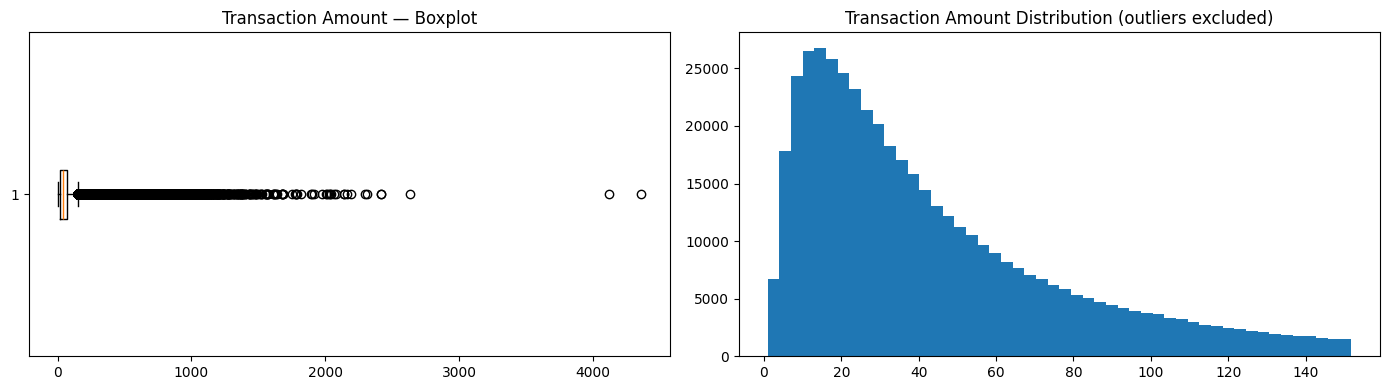

In [11]:
q1 = txn["transaction_amount"].quantile(0.25)
q3 = txn["transaction_amount"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

txn["is_amount_outlier"] = (txn["transaction_amount"] < lower_bound) | (txn["transaction_amount"] > upper_bound)

print(f"IQR bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Outlier transactions: {txn['is_amount_outlier'].sum():,} ({txn['is_amount_outlier'].mean()*100:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].boxplot(txn["transaction_amount"], vert=False)
ax[0].set_title("Transaction Amount — Boxplot")
ax[1].hist(txn.loc[~txn["is_amount_outlier"], "transaction_amount"], bins=50)
ax[1].set_title("Transaction Amount Distribution (outliers excluded)")
plt.tight_layout()
plt.show()


# 5. RFM Customer Segmentation

**Recency —** days since last transaction

 **Frequency —** number of transactions

 **Monetary —** total approved spend


Each dimension is scored 1–5 with quantile binning, combined into an RFM score, and mapped to actionable business segments (Champions, Loyal, At Risk, etc.) — this is the analytical core referenced in the resume bullet.

In [12]:
snapshot_date = txn["transaction_date"].max() + pd.Timedelta(days=1)

approved_txn = txn[txn["is_approved"]]

rfm = approved_txn.groupby("customer_id").agg(
    recency_days=("transaction_date", lambda x: (snapshot_date - x.max()).days),
    frequency=("transaction_id", "count"),
    monetary=("transaction_amount", "sum")
).reset_index()

rfm.describe()


,customer_id,recency_days,frequency,monetary
count,14525.000000,14525.000000,14525.000000,14525.000000
mean,7495.454871,77.543890,32.040620,1935.497787
std,4332.893180,131.173365,31.659058,1962.020233
min,1.000000,1.000000,1.000000,1.420000
25%,3741.000000,10.000000,9.000000,533.630000
50%,7496.000000,28.000000,22.000000,1325.500000
75%,11250.000000,81.000000,44.000000,2703.850000
max,15000.000000,908.000000,288.000000,18194.760000


In [32]:
# # Score each dimension 1-5 (5 = best). Recency is inverted: fewer days = higher score.
rfm["R_score"] = pd.qcut(
    rfm["recency_days"].rank(method="first"),
    5,
    labels=[5,4,3,2,1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1,2,3,4,5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1,2,3,4,5]
).astype(int)

rfm["RFM_score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)
rfm["RFM_total"] = rfm[["R_score", "F_score", "M_score"]].sum(axis=1)



def segment_customer(row):
    r, f, m = row["R_score"], row["F_score"], row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 3 and m >= 3:
        return "Loyal Customers"

    elif r >= 4 and f <= 2:
        return "New / Promising"

    elif r <= 2 and f >= 4 and m >= 4:
        return "At Risk"

    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost"

    elif r <= 2:
        return "Hibernating"

    else:
        return "Needs Attention"


rfm["segment"] = rfm.apply(segment_customer, axis=1)
rfm["segment"].value_counts()


,count
segment,
Lost,3812
Champions,3613
Loyal Customers,3075
Hibernating,1462
Needs Attention,1174
New / Promising,853
At Risk,536


In [33]:
rfm[["customer_id", "R_score", "F_score", "M_score"]].to_csv(
    "python_scores.csv",
    index=False
)

In [34]:
print(rfm["R_score"].value_counts().sort_index())
print(rfm["F_score"].value_counts().sort_index())
print(rfm["M_score"].value_counts().sort_index())

R_score
1    2905
2    2905
3    2905
4    2905
5    2905
Name: count, dtype: int64
F_score
1    2905
2    2905
3    2905
4    2905
5    2905
Name: count, dtype: int64
M_score
1    2905
2    2905
3    2905
4    2905
5    2905
Name: count, dtype: int64


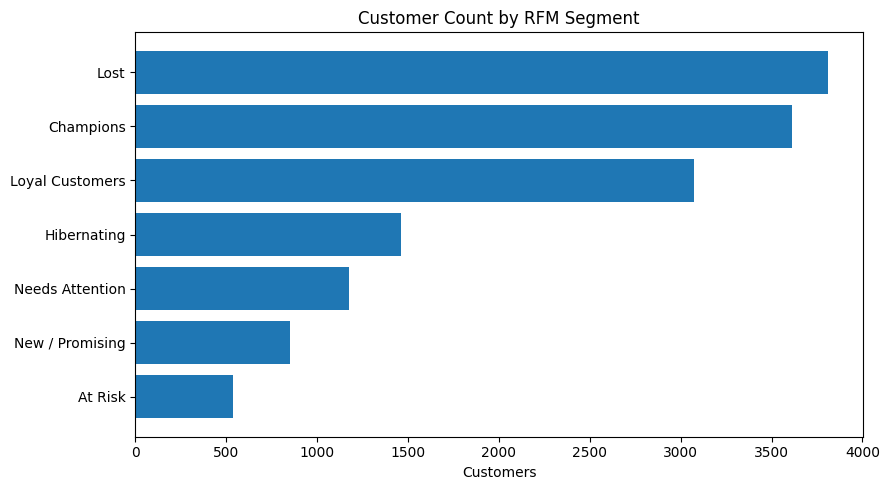

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))
seg_counts = rfm["segment"].value_counts().sort_values()
ax.barh(seg_counts.index, seg_counts.values)
ax.set_title("Customer Count by RFM Segment")
ax.set_xlabel("Customers")
plt.tight_layout()
plt.show()


# 6. KPI Calculation

Executive-level KPIs that will anchor the Tableau dashboard.

In [36]:
monthly_kpis = (approved_txn
    .groupby("txn_year_month")
    .agg(active_customers=("customer_id", "nunique"),
         revenue=("transaction_amount", "sum"),
         txn_count=("transaction_id", "count"))
    .reset_index())
monthly_kpis["avg_ticket"] = monthly_kpis["revenue"] / monthly_kpis["txn_count"]

fraud_rate = txn.groupby("txn_year_month")["is_fraud"].mean().reset_index(name="fraud_rate")
approval_rate = txn.groupby("txn_year_month")["is_approved"].mean().reset_index(name="approval_rate")

kpi_summary = (monthly_kpis
               .merge(fraud_rate, on="txn_year_month")
               .merge(approval_rate, on="txn_year_month"))

kpi_summary.head(12)


,txn_year_month,active_customers,revenue,txn_count,avg_ticket,fraud_rate,approval_rate
0,2024-01,7719,967820.73,15968,60.610016,0.002557,0.928102
1,2024-02,7431,906193.13,14728,61.528594,0.003727,0.930385
2,2024-03,7663,951335.82,15769,60.329496,0.003008,0.930050
3,2024-04,7514,915531.13,15263,59.983695,0.003484,0.933003
4,2024-05,7674,953005.80,15901,59.933702,0.003049,0.932391
5,2024-06,7566,917176.84,15213,60.289019,0.002198,0.928868
6,2024-07,7708,968311.98,15817,61.219699,0.003420,0.932661
7,2024-08,7709,952711.13,15786,60.351649,0.004116,0.928151
8,2024-09,7505,911761.45,15188,60.031699,0.002448,0.929441
9,2024-10,7602,956815.56,15864,60.313638,0.003468,0.932409


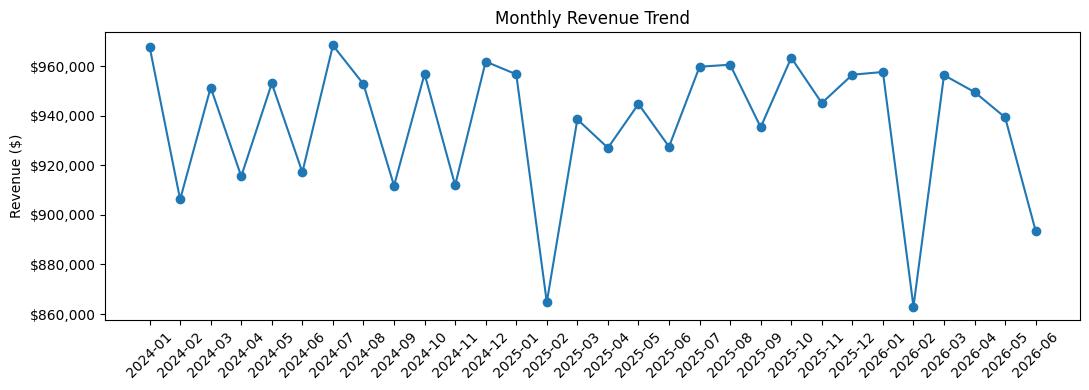

In [37]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(kpi_summary["txn_year_month"], kpi_summary["revenue"], marker="o")
ax.set_title("Monthly Revenue Trend")
ax.set_ylabel("Revenue ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [38]:
# Retention: % of customers active in month T who were also active in month T-1
active_by_month = approved_txn.groupby("txn_year_month")["customer_id"].apply(set).sort_index()
months = active_by_month.index.tolist()

retention = []
for i in range(1, len(months)):
    prev_set, curr_set = active_by_month.iloc[i-1], active_by_month.iloc[i]
    rate = len(prev_set & curr_set) / len(prev_set) if len(prev_set) else np.nan
    retention.append({"month": months[i], "retention_rate": rate})

retention_df = pd.DataFrame(retention)
retention_df.head(12)


,month,retention_rate
0,2024-02,0.662262
1,2024-03,0.683892
2,2024-04,0.668407
3,2024-05,0.682992
4,2024-06,0.670315
5,2024-07,0.686889
6,2024-08,0.684743
7,2024-09,0.666883
8,2024-10,0.673951
9,2024-11,0.662852


# 7. Export Processed Data for Tableau

Write clean, analysis-ready CSVs that Tableau will connect to directly (rather than raw transactional data), keeping the dashboard fast and the logic auditable.

In [39]:
rfm.to_csv(f"{DATA_DIR}/processed_customer_rfm_segments.csv", index=False)
kpi_summary.to_csv(f"{DATA_DIR}/processed_monthly_kpis.csv", index=False)
retention_df.to_csv(f"{DATA_DIR}/processed_retention.csv", index=False)

txn_export_cols = ["transaction_id", "customer_id", "merchant_id", "transaction_date",
                    "transaction_amount", "transaction_type", "transaction_status",
                    "is_fraud", "category_name", "category_group", "state", "city",
                    "income_bracket", "txn_year_month", "is_amount_outlier"]
txn[txn_export_cols].to_csv(f"{DATA_DIR}/processed_transactions_enriched.csv", index=False)

print("Exported: processed_customer_rfm_segments.csv, processed_monthly_kpis.csv, "
      "processed_retention.csv, processed_transactions_enriched.csv")


Exported: processed_customer_rfm_segments.csv, processed_monthly_kpis.csv, processed_retention.csv, processed_transactions_enriched.csv


# Summary of Findings (fill in with your actual numbers after running)


* **Segmentation:** X% of customers are "Champions" driving Y% of total revenue — a natural target for loyalty/retention campaigns.

* **Revenue trend:** Monthly revenue grew from  𝑋𝑡𝑜 Y over the observed window.


* **Retention:**  Average month-over-month retention sits around Z%.


* **Fraud:** Fraud rate is highest among Online transactions at high-risk merchants — supports tighter step-up authentication rules there.

* **Recommendation:** Prioritize win-back campaigns for the "At Risk" segment (high past frequency, recent inactivity) before they fully churn.



